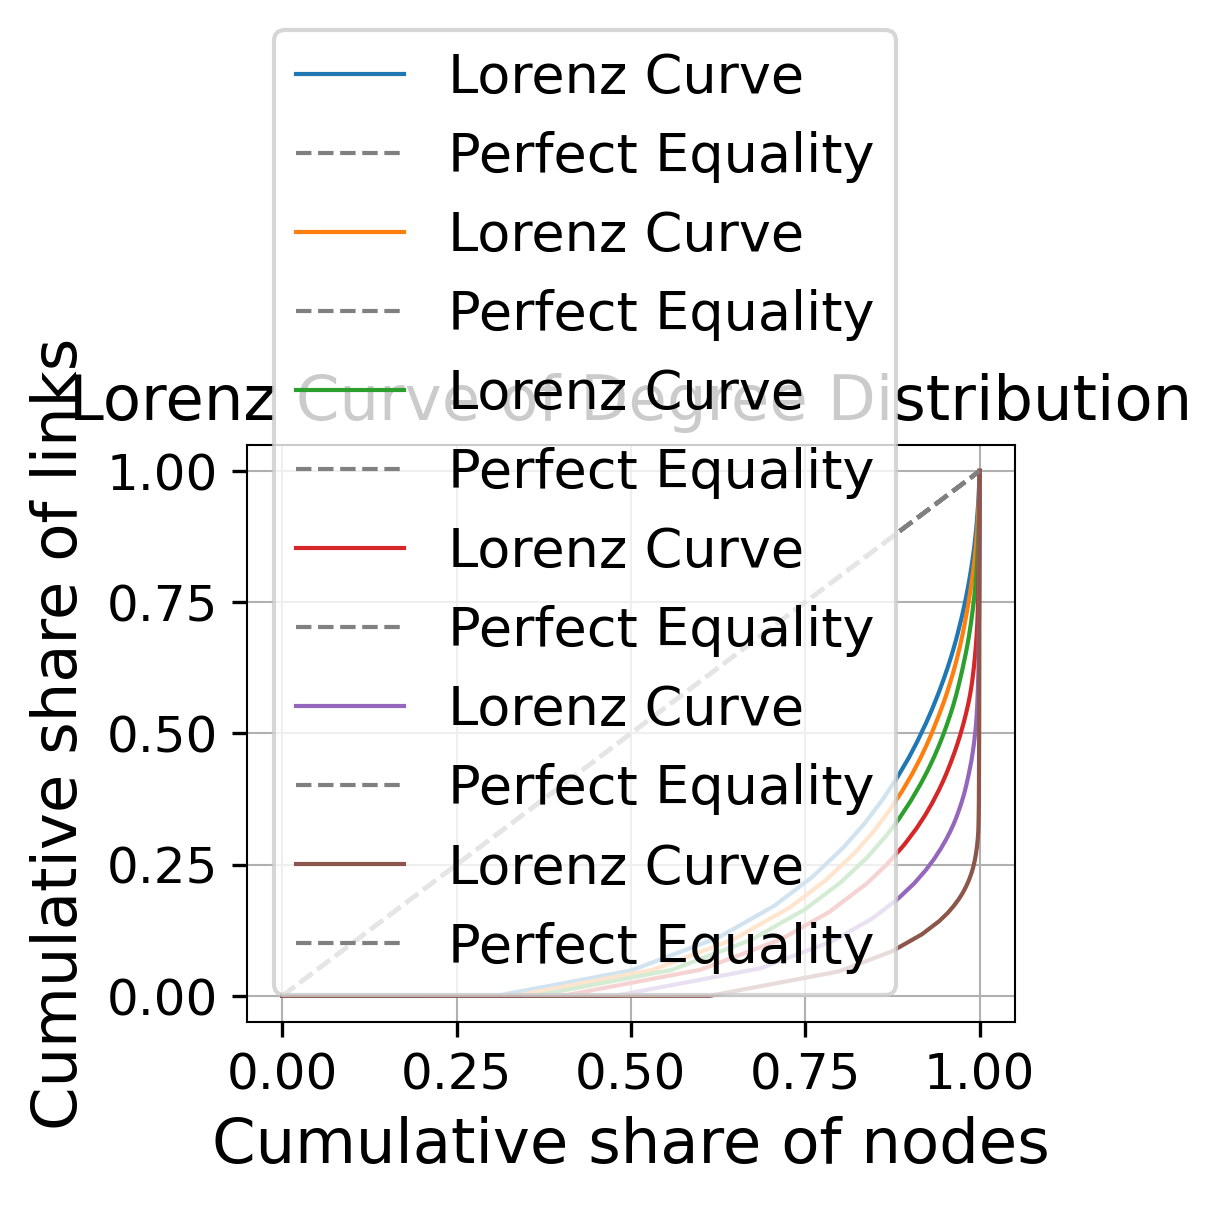

In [5]:
import numpy as np
import matplotlib.pyplot as plt
N = 5e3
# alpha = 1.3
m = 4

def prob_attach(k, alpha):
    """
    Calculate the probability of attaching a new node to an existing node
    with degree k.
    """
    kernel = np.array([k[i]**alpha for i in range(len(k))])
    return kernel / sum(kernel)

def step(k, alpha, m):
    probabilities = prob_attach(k, alpha)
    rng = np.random.default_rng()
    targets = rng.choice(np.arange(len(probabilities)), m, p=probabilities, replace=False)
    for i in targets:
        k[i] += 1
    k.append(m)
    return k

def calculate_gini(arr):
    arr = np.array(arr)
    if len(arr) == 0:
        return None  # または 0.0 にするなど応相談
    arr.sort()
    rank = np.arange(1, len(arr) + 1)
    weighted = arr * rank
    n = len(arr)
    total = arr.sum()
    if total == 0 or n == 0:
        return None  # または 0.0 にするなど応相談
    gini = (2 * weighted.sum() / total - (n + 1)) / n

    return gini

# simulation on a creak graph
def plot_lorenz_curve(degrees):
    x = np.sort(np.array(degrees))
    # x = x[x > 0]  # avoid zero-degree if any
    cumx = np.cumsum(x)
    cumx = cumx / cumx[-1]
    plt.plot(np.linspace(0, 1, len(cumx)), cumx, label="Lorenz Curve")
    plt.plot([0, 1], [0, 1], '--', color='gray', label="Perfect Equality")
    plt.xlabel("Cumulative share of nodes")
    plt.ylabel("Cumulative share of links")
    plt.title("Lorenz Curve of Degree Distribution")
    plt.legend()
    plt.grid(True)
    # plt.show()


alphas = [0.9, 1.0, 1.1, 1.2, 1.3, 1.4]
gini_dict = []
for alpha in alphas:
    simulated_ginis = []
    for trial in range(10):
    # for m in range(1, 11):
        k = [m] * (m + 1)
        for i in range(int(N)):
            k = step(k, alpha, m)
        # print(np.array(k)/m )
        # plt.hist(np.array(k)/m , bins=100, alpha=0.1)
        # plt.xscale('log')
        # plt.yscale('log')
        gini = calculate_gini(np.array(k) / m -1)
        simulated_ginis.append(gini)
    plot_lorenz_curve(np.array(k)/m -1)

    simulated_ginis = np.array(simulated_ginis)
    gini_dict.append({"alpha": alpha, "mean": simulated_ginis.mean(), "std": simulated_ginis.std()})

plt.show()

In [6]:
import polars as pl
gini_df = pl.json_normalize(gini_dict)
gini_df

alpha,mean,std
f64,f64,f64
0.9,0.707116,0.003029
1.0,0.733512,0.002614
1.1,0.767454,0.002504
1.2,0.81235,0.003552
1.3,0.876014,0.002599
1.4,0.937184,0.003574


['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


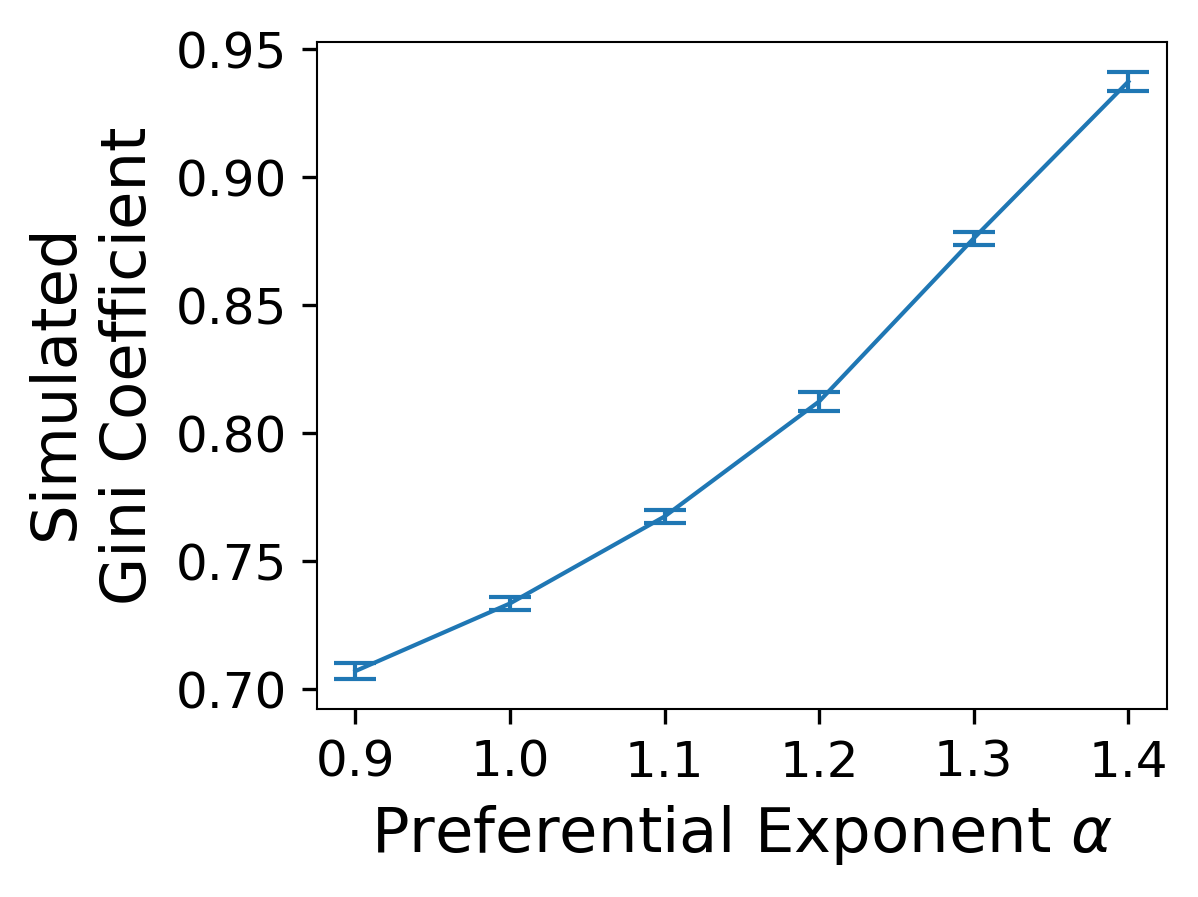

In [7]:
from matplotlib import pyplot as plt
import numpy as np
import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rc('axes', titlesize=15, labelsize=15)      # Title font size
plt.rc('xtick', labelsize=12)     # X-axis tick font size
plt.rc('ytick', labelsize=12)     # Y-axis tick font size
plt.rc('legend', fontsize=13)     # Legend font sizplt

plt.figure(figsize=(4, 3))
print(plt.rcParams['axes.prop_cycle'].by_key()['color'])
# plt.plot(gini_df["alpha"], gini_df["mean"])
plt.errorbar(gini_df["alpha"], gini_df["mean"], yerr=gini_df["std"], capsize=5, label='Gini Coefficient')
plt.xticks(gini_df["alpha"])
plt.ylabel("Simulated \n Gini Coefficient")
plt.xlabel("Preferential Exponent $ \\alpha $")
plt.tight_layout()

In [ ]:
# print(0.8392315369261478 / 0.6778640949554896)
# print(0.8483161838161839 /0.6877314768771754)
# print(0.8337723739729068 /0.6907329126536038)
# print(0.8383372063968015 /0.6914548616305163)

1.238052794316026
1.2334991378730917
1.2070836045292603
1.2124250662146228


In [137]:
arr = np.array(k)/m -1

arr.sort()
rank = np.arange(1, len(arr) + 1)
weighted = arr * rank
n = len(arr)
total = arr.sum()
gini = (2 * weighted.sum() / total - (n + 1)) / n


In [140]:
gini

0.8590444426687976

In [ ]:
N = 5e3
m = 3
alpha = 0.9
(0.6227949597952315, 0.004686094036472272) 1e3
(0.6264821441574622, 0.0021798082813449617) 5e3
(0.6266643004583518, 0.001507109498376645) 1e4

alpha = 1.2
(0.7268947282845604, 0.0011690301037165834)

alpha = 1.5
(0.7483726799275013, 0.00013806371161258275)

alpha = 1.8
(0.7491292796715415, 3.7348900371627483e-05)


In [ ]:
N = 5e3
m = 4
alpha = 0.9
(0.6768474135295982, 0.0012969058480368618)

alpha = 1.2
(0.7814414737099172, 0.0006331223425032938)

alpha = 1.5
(0.7983044897809339, 7.565961976670551e-05)


In [ ]:
10^4 
alpha=1.0 (0.5738266010341985, 0.001382341868381681)
10^3, m = 3
alpha=1.0 (0.5667606328739185, 0.0044870662019431875) (m=10: (0.8314309163886414, 0.0027045595426937728), m=5: (0.7417823539425491, 0.004011547378629812), m=3: (0.6502131799214833, 0.005142367944801378))
alpha=1.3 (0.6382903193973881, 0.003213701247110812)
alpha=1.4 (0.658067651283401, 0.0012696328880566336)
aloha=1.5 (0.6582605396752299, 0.0012006227737061486) (m=3: (0.741836152193773, 0.0006371844649962126))
5e3
alpha=1.3 (0.6556790633700399, 0.0011964298306383402)

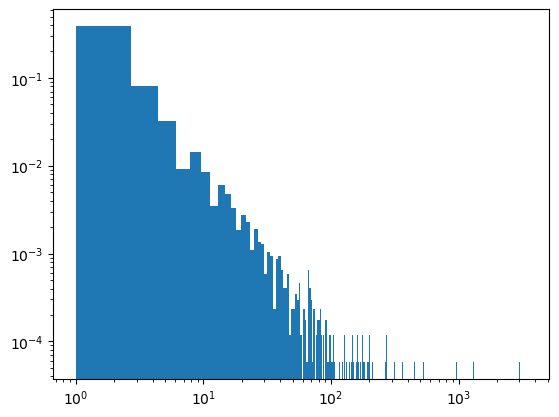

In [31]:
import matplotlib.pyplot as plt
plt.hist(k, bins=2000, density=True)
plt.xscale('log')

plt.yscale('log')